In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

In [3]:
data=pd.read_csv("/content/insurance.csv")

In [4]:
data.shape

(1338, 7)

In [5]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [6]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [8]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [9]:
data.nunique()

,0
age,47
sex,2
bmi,548
children,6
smoker,2
region,4
charges,1337


In [10]:
print("Sex:", data['sex'].unique())
print("Smoker:", data['smoker'].unique())
print("Region:", data['region'].unique())

Sex: ['female' 'male']
Smoker: ['yes' 'no']
Region: ['southwest' 'southeast' 'northwest' 'northeast']


In [11]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [12]:
missing_count = data.isnull().sum()

missing_percentage = (missing_count / len(data)) * 100

print(missing_percentage)

age         0.0
sex         0.0
bmi         0.0
children    0.0
smoker      0.0
region      0.0
charges     0.0
dtype: float64


In [13]:
data.duplicated().sum()

np.int64(1)

In [14]:
data[data.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [15]:
print("Rows before:", len(data))

Rows before: 1338


In [16]:
data = data.drop_duplicates()


In [17]:
print("Rows after:", len(data))

Rows after: 1337


In [18]:
data.duplicated().sum()

np.int64(0)

Data Cleaning

In [19]:
print(data['sex'].unique())
print(data['smoker'].unique())
print(data['region'].unique())

['female' 'male']
['yes' 'no']
['southwest' 'southeast' 'northwest' 'northeast']


In [20]:
data.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [21]:
print("Minimum Age:", data['age'].min())
print("Minimum BMI:", data['bmi'].min())
print("Minimum Children:", data['children'].min())
print("Minimum Charges:", data['charges'].min())

Minimum Age: 18
Minimum BMI: 15.96
Minimum Children: 0
Minimum Charges: 1121.8739


In [22]:
print("Maximum Age:", data['age'].max())
print("Maximum BMI:", data['bmi'].max())
print("Maximum Children:", data['children'].max())
print("Maximum Charges:", data['charges'].max())

Maximum Age: 64
Maximum BMI: 53.13
Maximum Children: 5
Maximum Charges: 63770.42801


Outlier Detection & Handling

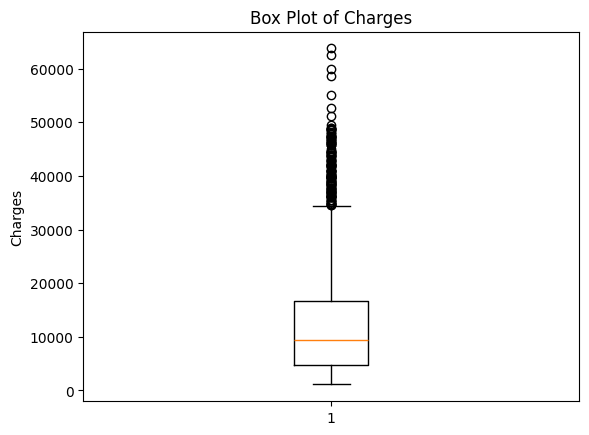

In [23]:
plt.boxplot(data['charges'])
plt.title('Box Plot of Charges')
plt.ylabel('Charges')
plt.show()

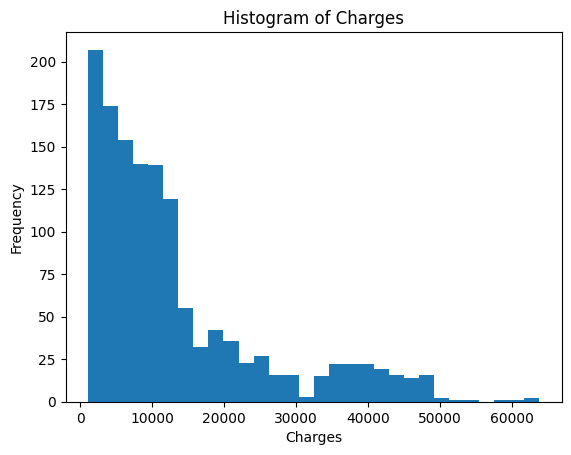

In [24]:
plt.hist(data['charges'], bins=30)
plt.title('Histogram of Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()

In [25]:
Q1 = data['charges'].quantile(0.25)
Q3 = data['charges'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 4746.344
Q3: 16657.71745
IQR: 11911.37345
Lower Bound: -13120.716174999998
Upper Bound: 34524.777625


In [26]:
outliers = data[
    (data['charges'] < lower_bound) |
    (data['charges'] > upper_bound)
]

print("Number of Outliers:", len(outliers))

Number of Outliers: 139


In [27]:
Q1_bmi = data['bmi'].quantile(0.25)
Q3_bmi = data['bmi'].quantile(0.75)

IQR_bmi = Q3_bmi - Q1_bmi

lower_bmi = Q1_bmi - 1.5 * IQR_bmi
upper_bmi = Q3_bmi + 1.5 * IQR_bmi

outliers_bmi = data[
    (data['bmi'] < lower_bmi) |
    (data['bmi'] > upper_bmi)
]

print("Lower Bound:", lower_bmi)
print("Upper Bound:", upper_bmi)
print("Number of Outliers:", len(outliers_bmi))

Lower Bound: 13.674999999999994
Upper Bound: 47.31500000000001
Number of Outliers: 9


In [28]:
Q1_age = data['age'].quantile(0.25)
Q3_age = data['age'].quantile(0.75)

IQR_age = Q3_age - Q1_age

lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

outliers_age = data[
    (data['age'] < lower_age) |
    (data['age'] > upper_age)
]

print("Lower Bound:", lower_age)
print("Upper Bound:", upper_age)
print("Number of Outliers:", len(outliers_age))

Lower Bound: -9.0
Upper Bound: 87.0
Number of Outliers: 0


In [29]:
Q1_children = data['children'].quantile(0.25)
Q3_children = data['children'].quantile(0.75)

IQR_children = Q3_children - Q1_children

lower_children = Q1_children - 1.5 * IQR_children
upper_children = Q3_children + 1.5 * IQR_children

outliers_children = data[
    (data['children'] < lower_children) |
    (data['children'] > upper_children)
]

print("Lower Bound:", lower_children)
print("Upper Bound:", upper_children)
print("Number of Outliers:", len(outliers_children))

Lower Bound: -3.0
Upper Bound: 5.0
Number of Outliers: 0


Categorical Encoding

In [30]:
data[['sex', 'smoker', 'region']].head()

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest


In [31]:
pd.get_dummies(data['sex'], dtype=int)

,female,male
0,1,0
1,0,1
2,0,1
3,0,1
4,0,1
...,...,...
1333,0,1
1334,1,0
1335,1,0
1336,1,0


In [32]:
encoded_data = pd.get_dummies(
    data,
    columns=['sex', 'smoker', 'region'],
    dtype=int
)

encoded_data.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0


In [33]:
print("Original Shape:", data.shape)
print("Encoded Shape:", encoded_data.shape)

Original Shape: (1337, 7)
Encoded Shape: (1337, 12)


In [34]:
X = data[['age', 'bmi', 'children']]
y = data['charges']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [36]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1069, 3)
Testing Data: (268, 3)


In [37]:
scaler = StandardScaler()

In [38]:
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [39]:
print("Before Scaling:")
print(X_train.head())

print("\nAfter Scaling:")
print(X_train_scaled[:5])

Before Scaling:
      age     bmi  children
1114   23  24.510         0
968    21  25.745         2
599    52  37.525         2
170    63  41.470         0
275    47  26.600         2

After Scaling:
[[-1.1576804  -0.99692768 -0.90790804]
 [-1.30061876 -0.79276204  0.7669042 ]
 [ 0.91492586  1.15466402  0.7669042 ]
 [ 1.70108686  1.80683684 -0.90790804]
 [ 0.55757996 -0.6514166   0.7669042 ]]


In [40]:
minmax_scaler = MinMaxScaler()

In [41]:
X_train_minmax = minmax_scaler.fit_transform(X_train)

In [42]:
X_test_minmax = minmax_scaler.transform(X_test)

In [43]:
print("Before Scaling:")
print(X_train.head())

print("\nAfter MinMax Scaling:")
print(X_train_minmax[:5])

Before Scaling:
      age     bmi  children
1114   23  24.510         0
968    21  25.745         2
599    52  37.525         2
170    63  41.470         0
275    47  26.600         2

After MinMax Scaling:
[[0.10869565 0.23002421 0.        ]
 [0.06521739 0.26324993 0.4       ]
 [0.73913043 0.58017218 0.4       ]
 [0.97826087 0.68630616 0.        ]
 [0.63043478 0.28625235 0.4       ]]


In [44]:
print("Final Rows:", len(data))
print("Missing Values:", data.isnull().sum().sum())
print("Duplicates:", data.duplicated().sum())
print("Shape:", data.shape)

Final Rows: 1337
Missing Values: 0
Duplicates: 0
Shape: (1337, 7)


In [45]:
print("Negative Age:", (data['age'] < 0).sum())
print("Negative BMI:", (data['bmi'] < 0).sum())
print("Negative Children:", (data['children'] < 0).sum())
print("Negative Charges:", (data['charges'] < 0).sum())

Negative Age: 0
Negative BMI: 0
Negative Children: 0
Negative Charges: 0


In [47]:
data.to_csv('insurance_cleaned.csv', index=False)